In [1]:
#EXP 3 TANUSHRI BHISE A28

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# Load the dataset
data = pd.read_csv("mnist.csv")

# Display first 5 rows
print(data.head())

# Display shape
print("Dataset Shape:", data.shape)

   label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
0      7    0    0    0    0    0    0    0    0    0  ...      0      0   
1      2    0    0    0    0    0    0    0    0    0  ...      0      0   
2      1    0    0    0    0    0    0    0    0    0  ...      0      0   
3      0    0    0    0    0    0    0    0    0    0  ...      0      0   
4      4    0    0    0    0    0    0    0    0    0  ...      0      0   

   28x21  28x22  28x23  28x24  28x25  28x26  28x27  28x28  
0      0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0      0  

[5 rows x 785 columns]
Dataset Shape: (10000, 785)


In [3]:
# Target variable
y = data["label"]

# Features
X = data.drop("label", axis=1)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (10000, 784)
Target Shape: (10000,)


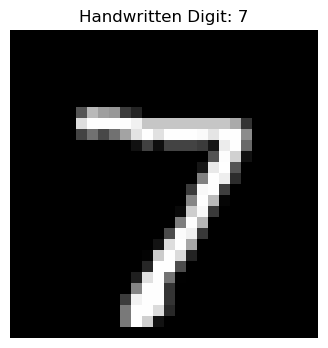

In [4]:
# Select first image
image = X.iloc[0].values.reshape(28, 28)

# Display image
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Handwritten Digit: " + str(y.iloc[0]))
plt.axis("off")
plt.show()

In [5]:
X = X / 255.0

print(X.head())

   1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  1x10  ...  28x19  28x20  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  ...    0.0    0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  ...    0.0    0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  ...    0.0    0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  ...    0.0    0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  ...    0.0    0.0   

   28x21  28x22  28x23  28x24  28x25  28x26  28x27  28x28  
0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0  
1    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0  
2    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0  
3    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0  
4    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0  

[5 rows x 784 columns]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 784)
Testing Data: (2000, 784)


In [7]:
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

In [8]:
print("Training SVM...")

svm_model.fit(X_train, y_train)

print("Training completed!")

Training SVM...
Training completed!


In [9]:
y_pred = svm_model.predict(X_test)

print("Predicted Labels:")
print(y_pred[:20])

print("Actual Labels:")
print(y_test.iloc[:20].values)

Predicted Labels:
[1 2 4 2 1 0 6 6 6 6 0 8 4 9 8 7 6 8 0 7]
Actual Labels:
[1 2 4 2 1 0 6 6 6 6 0 8 4 9 8 7 6 8 0 7]


In [10]:
accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

SVM Accuracy: 0.9705
Accuracy Percentage: 97.05 %


In [11]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       196
           1       0.99      1.00      1.00       227
           2       0.98      0.97      0.97       206
           3       0.97      0.98      0.97       202
           4       0.94      0.96      0.95       196
           5       0.98      0.95      0.97       178
           6       0.97      0.98      0.97       192
           7       0.96      0.95      0.95       206
           8       0.97      0.97      0.97       195
           9       0.96      0.96      0.96       202

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



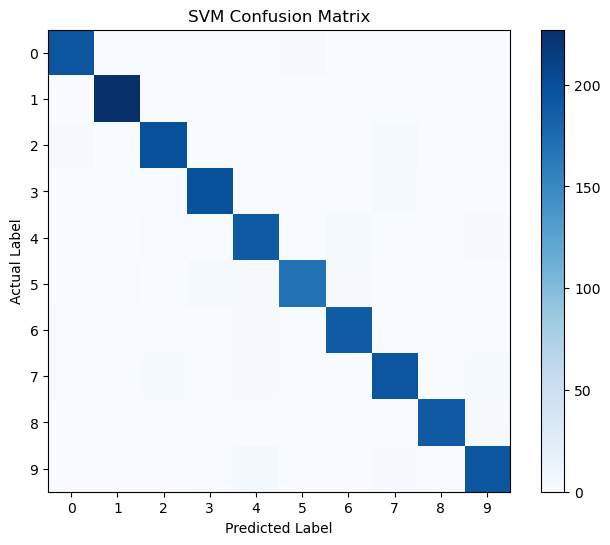

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")

plt.xticks(range(10))
plt.yticks(range(10))

plt.show()

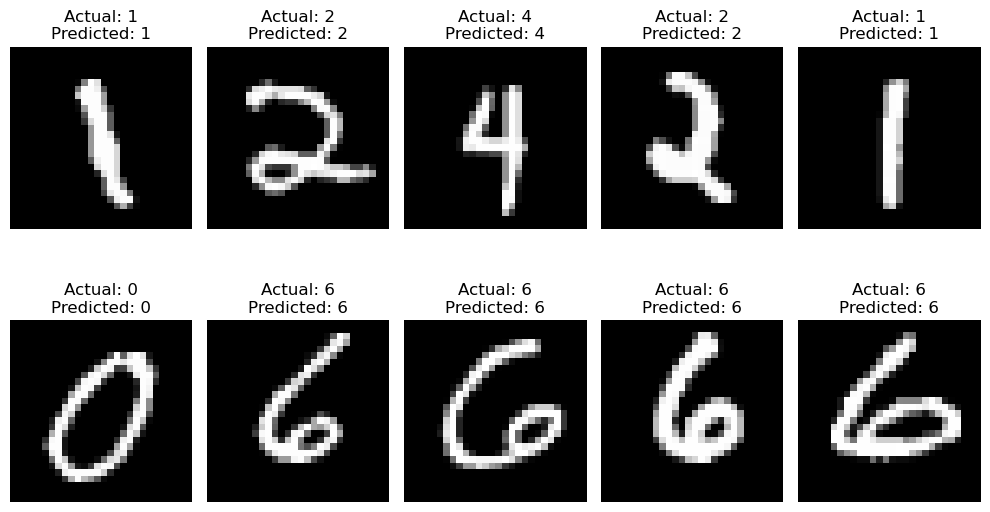

In [13]:
plt.figure(figsize=(10, 6))

for i in range(10):
    image = X_test.iloc[i].values.reshape(28, 28)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(
        f"Actual: {y_test.iloc[i]}\nPredicted: {y_pred[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()